# AI Cohort Beginner Level Project

Objective: Demonstrate learned topics from the course of of Supervised Learning Algorithms and Advanced Learning Algorithms courses. To do that, I will develop a neural network to classify objects given a the Fashion-MNIST dataset. The dataset contains 70,000 labeld examples.

Dataset: https://www.kaggle.com/datasets/zalando-research/fashionmnist

Lets import all packages needed to build our model.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.activations import relu,linear
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam


In [4]:
data = np.loadtxt('data/fashion-mnist_train.csv', delimiter=',',skiprows=1)

In [6]:
x = data[:, 1:] #Training data
y = data[:, 0] #Label data
print(f'x shape is {x.shape} \n')
print(f'y shape is {y.shape}\n')


x shape is (60000, 784) 

y shape is (60000,)



In [7]:
#Convert y into a 2-D array
y = np.expand_dims(y, axis=1)
y.shape

(60000, 1)

We need to make sure that the data does not contains missing values.

In [8]:
nan_counts = np.sum(np.isnan(data))
print(f'Training data has {nan_counts} missing values')

Training data has 0 missing values


Lets render a random subset of images from the dataset and their respective label.
0 T-shirt/top
1 Trouser
2 Pullover
3 Dress
4 Coat
5 Sandal
6 Shirt
7 Sneaker
8 Bag
9 Ankle boot

In [23]:
label = {
    0:"T-shirt/top",
    1:"Trouser",
    2:"Pullover",
    3:"Dress",
    4:"Coat",
    5:"Sandal",
    6:"Shirt",
    7:"Sneaker",
    8:"Bag",
    9:"Ankle boot"
}


/var/folders/_x/v31jblm52cq579qc0dzpptzm0000gn/T/ipykernel_19827/4265254093.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ax.set_title(label[int(y[idx])])


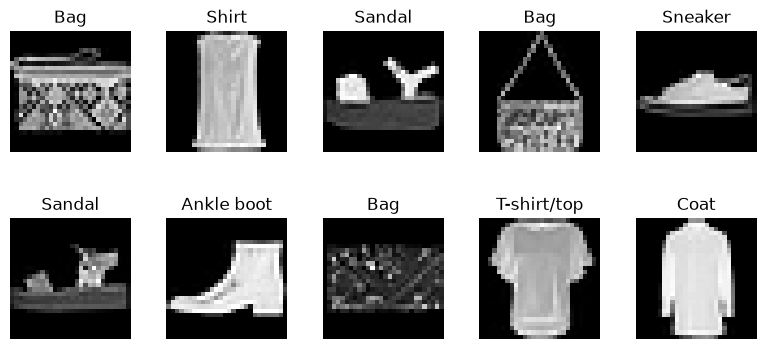

In [25]:
#Render 1 image
rng = np.random.default_rng(seed=31)
num_examples = 10
random_indices = rng.choice(x.shape[0], size=num_examples, replace=False)
#random_images = x[random_indices]
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, idx in zip(axes.flat, random_indices):
    img = x[idx].reshape(28,28)
    ax.imshow(img, cmap="gray")
    ax.set_title(label[int(y[idx])])
    ax.axis("off")

plt.subplots_adjust(wspace=0.05, hspace=0.55)
plt.show()

In [26]:
# Split data into training and validation set. Test set already exists.
#x_train, _x, y_train, y_ = split
